# CNN 128 — Redes Neurais (TrashNet)

Experimentos `cnn_128_sem` e `cnn_128_com` (integrante 3) e comparação com o MLP **na validação**.

Antes: **Ambiente de execução → Alterar tipo → GPU (T4)**.

Tudo fica salvo no seu Google Drive. Se o Colab cair, rode as células de novo: o treino continua da última época.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive
!test -d neural-network-project || git clone https://github.com/matheusvsmp/neural-network-project.git
%cd neural-network-project
!git pull
!ls

/content/drive/MyDrive
Cloning into 'neural-network-project'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 49 (delta 9), reused 45 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 2.58 MiB | 19.75 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/drive/MyDrive/neural-network-project
Already up to date.
01_eda_split.py  figuras     requirements.txt  treino_mlp_colab.ipynb
02_mlp.py	 historicos  saida_eda.txt
common.py	 README.md   split.json


Coloque `common.py` e `03_cnn.py` na pasta `neural-network-project` do seu Drive (se ainda não estiverem no repositório).

In [4]:
# Baixa o TrashNet (só na primeira vez)
!test -d dataset-resized || (git clone --depth 1 https://github.com/garythung/trashnet.git /content/trashnet && unzip -q /content/trashnet/data/dataset-resized.zip -d . && rm -rf __MACOSX)
!ls dataset-resized

Cloning into '/content/trashnet'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 22 (delta 0), reused 15 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 40.63 MiB | 18.11 MiB/s, done.
cardboard  glass  metal  paper	plastic  trash


In [5]:
import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Treino

Integrante 4 (resolução): `!python 03_cnn.py --exp cnn_256_sem cnn_512_sem` (se faltar memória, acrescente `--batch_size 16` e justifique no artigo).

In [6]:
!python 03_cnn.py


cnn_128_sem
W0000 00:00:1795385334.837745    6534 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 128, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 128, 32)    │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activatio

In [7]:
import json
for nome in ['cnn_128_sem', 'cnn_128_com']:
    m = json.load(open(f'historicos/{nome}.json'))['meta']
    print(nome, '| val F1 macro', round(m['val_f1_macro'], 3), '| val acc', round(m['val_accuracy'], 3),
          '| época salva', m['epoca_do_modelo_salvo'], 'de', m['epocas_rodadas'],
          '| min', round(m['tempo_total_treino_s']/60, 1), '| s/época', m['tempo_medio_por_epoca_s'],
          '| MB', m['tamanho_modelo_salvo_mb'], '| GPU', m['hardware']['gpu'])

cnn_128_sem | val F1 macro 0.646 | val acc 0.715 | época salva 61 de 71 | min 1.9 | s/época 1.61 | MB 0.49 | GPU ['Tesla T4']
cnn_128_com | val F1 macro 0.668 | val acc 0.689 | época salva 50 de 60 | min 1.4 | s/época 1.45 | MB 0.49 | GPU ['Tesla T4']


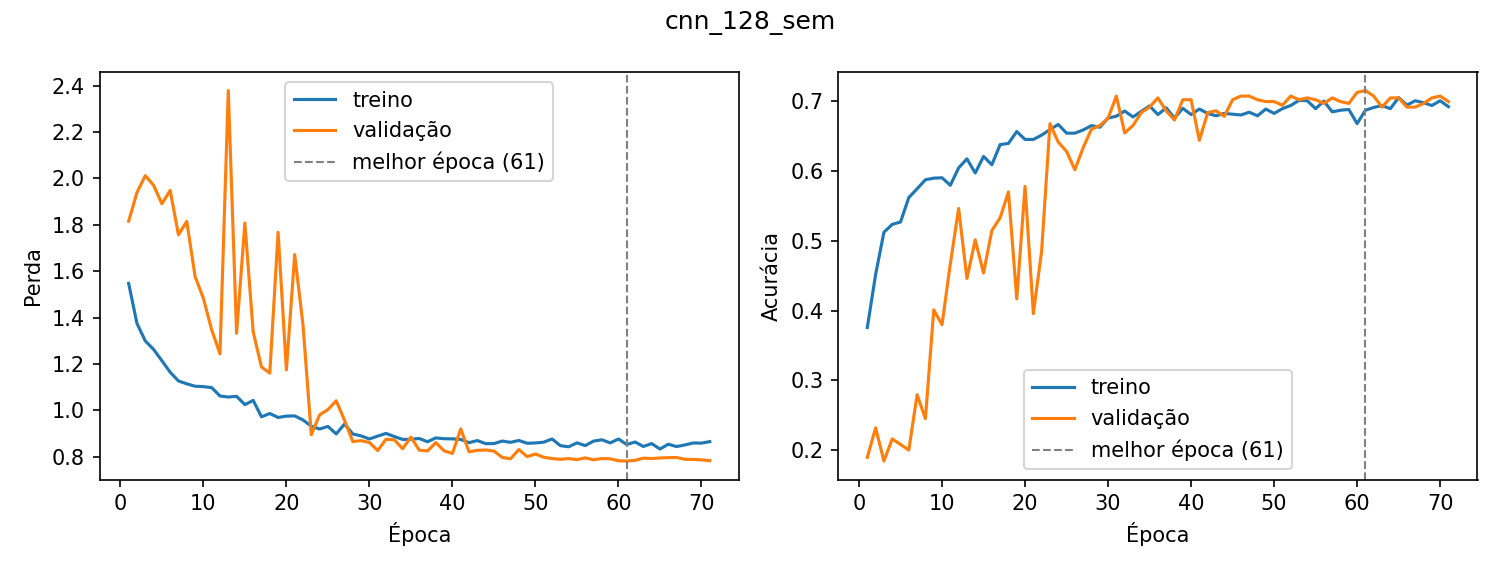

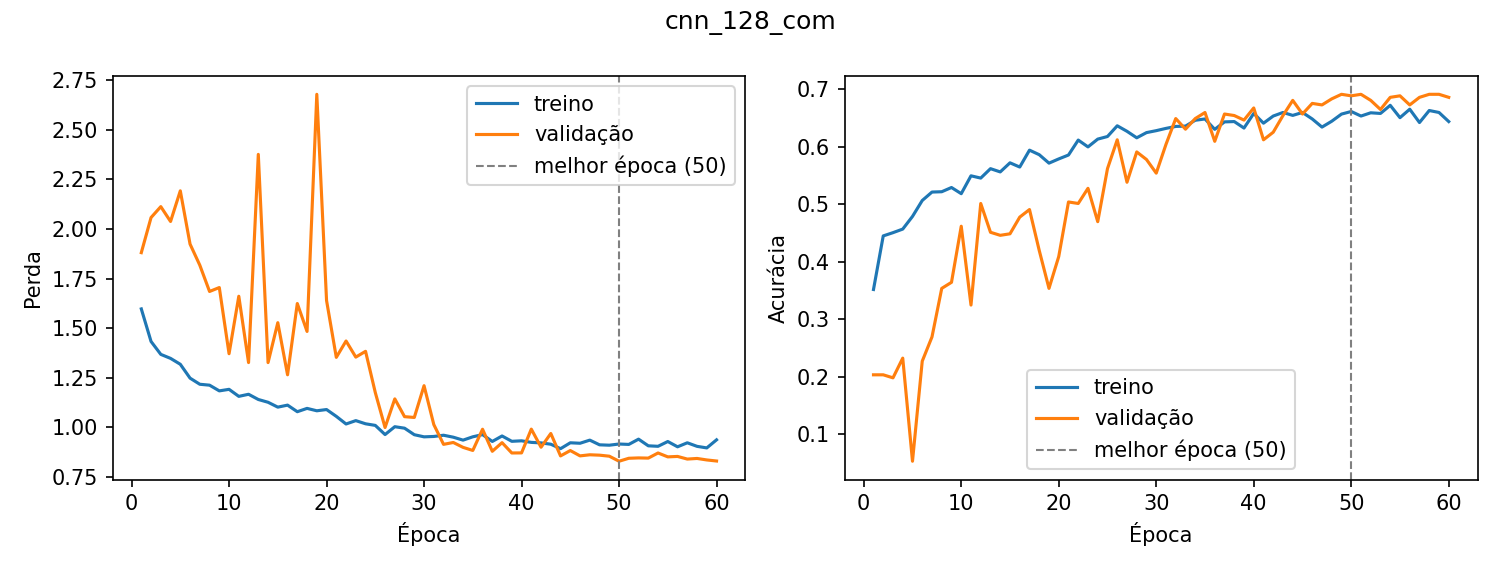

In [8]:
from IPython.display import Image, display
for nome in ['cnn_128_sem', 'cnn_128_com']:
    display(Image(f'figuras/curvas/{nome}.png'))

## Comparação MLP × CNN (só VALIDAÇÃO)

O conjunto de teste **não** é usado aqui — ele fica para o `05_resultados.py`, no final. Estas tabelas servem para o texto sobre CNN e pesos de classe.

In [9]:
import pandas as pd
from pathlib import Path

NOMES = ['mlp_128_sem', 'mlp_128_com', 'cnn_128_sem', 'cnn_128_com']
linhas = []
for nome in NOMES:
    p = Path(f'historicos/{nome}.json')
    if not p.exists():
        print('ainda não treinado:', nome)
        continue
    m = json.loads(p.read_text(encoding='utf-8'))['meta']
    linhas.append({'experimento': nome, 'val_f1_macro': m['val_f1_macro'], 'val_acc': m['val_accuracy'],
                   'época salva': m['epoca_do_modelo_salvo'], 'épocas': m['epocas_rodadas'],
                   'parâmetros': m['parametros_treinaveis'], 'MB': m['tamanho_modelo_salvo_mb'],
                   'tempo total (min)': round(m['tempo_total_treino_s'] / 60, 1),
                   's/época': m['tempo_medio_por_epoca_s']})
tabela = pd.DataFrame(linhas).set_index('experimento')
tabela.round(3)

,val_f1_macro,val_acc,época salva,épocas,parâmetros,MB,tempo total (min),s/época
experimento,,,,,,,,
mlp_128_sem,0.505,0.538,57,67,9471878,36.18,2.0,1.77
mlp_128_com,0.502,0.520,25,35,9471878,36.18,1.0,1.78
cnn_128_sem,0.646,0.715,61,71,110982,0.49,1.9,1.61
cnn_128_com,0.668,0.689,50,60,110982,0.49,1.4,1.45


### Efeito dos pesos de classe por classe (validação)

Precisão, recall e F1 por classe de cada modelo na validação, e a diferença **com − sem pesos** em cada arquitetura (atenção à classe **trash**).

In [10]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import precision_recall_fscore_support
from common import CLASSES, carregar_split, caminhos_e_rotulos, criar_dataset

split = carregar_split()
_, y_val = caminhos_e_rotulos(split, 'val')
ds_val = criar_dataset(split, 'val', 128)

por_classe = {}
for nome in NOMES:
    p = Path(f'modelos/{nome}.keras')
    if not p.exists():
        continue
    modelo = tf.keras.models.load_model(p, compile=False)
    y_pred = np.argmax(modelo.predict(ds_val, verbose=0), axis=1)
    pr, rc, f1, sup = precision_recall_fscore_support(y_val, y_pred, labels=range(len(CLASSES)), zero_division=0)
    por_classe[nome] = pd.DataFrame({'precisão': pr, 'recall': rc, 'F1': f1, 'suporte': sup}, index=CLASSES)
    print(f'\n{nome}')
    display(por_classe[nome].round(3))


cnn_128_sem


,precisão,recall,F1,suporte
glass,0.574,0.720,0.639,75
paper,0.714,0.955,0.817,89
cardboard,0.947,0.885,0.915,61
plastic,0.662,0.597,0.628,72
metal,0.800,0.516,0.627,62
trash,0.750,0.150,0.250,20



cnn_128_com


,precisão,recall,F1,suporte
glass,0.594,0.507,0.547,75
paper,0.752,0.854,0.800,89
cardboard,0.930,0.869,0.898,61
plastic,0.657,0.639,0.648,72
metal,0.816,0.500,0.620,62
trash,0.347,0.850,0.493,20


In [11]:
for arq in ['mlp', 'cnn']:
    sem, com = f'{arq}_128_sem', f'{arq}_128_com'
    if sem in por_classe and com in por_classe:
        dif = (por_classe[com][['precisão', 'recall', 'F1']] - por_classe[sem][['precisão', 'recall', 'F1']]).round(3)
        print(f'\n{arq.upper()}: com pesos − sem pesos (validação)')
        display(dif.style.background_gradient(cmap='RdYlGn', vmin=-0.3, vmax=0.3))


CNN: com pesos − sem pesos (validação)


,precisão,recall,F1
glass,0.019000,-0.213000,-0.092000
paper,0.038000,-0.101000,-0.017000
cardboard,-0.018000,-0.016000,-0.017000
plastic,-0.004000,0.042000,0.020000
metal,0.016000,-0.016000,-0.007000
trash,-0.403000,0.700000,0.243000


### Curvas de aprendizagem lado a lado

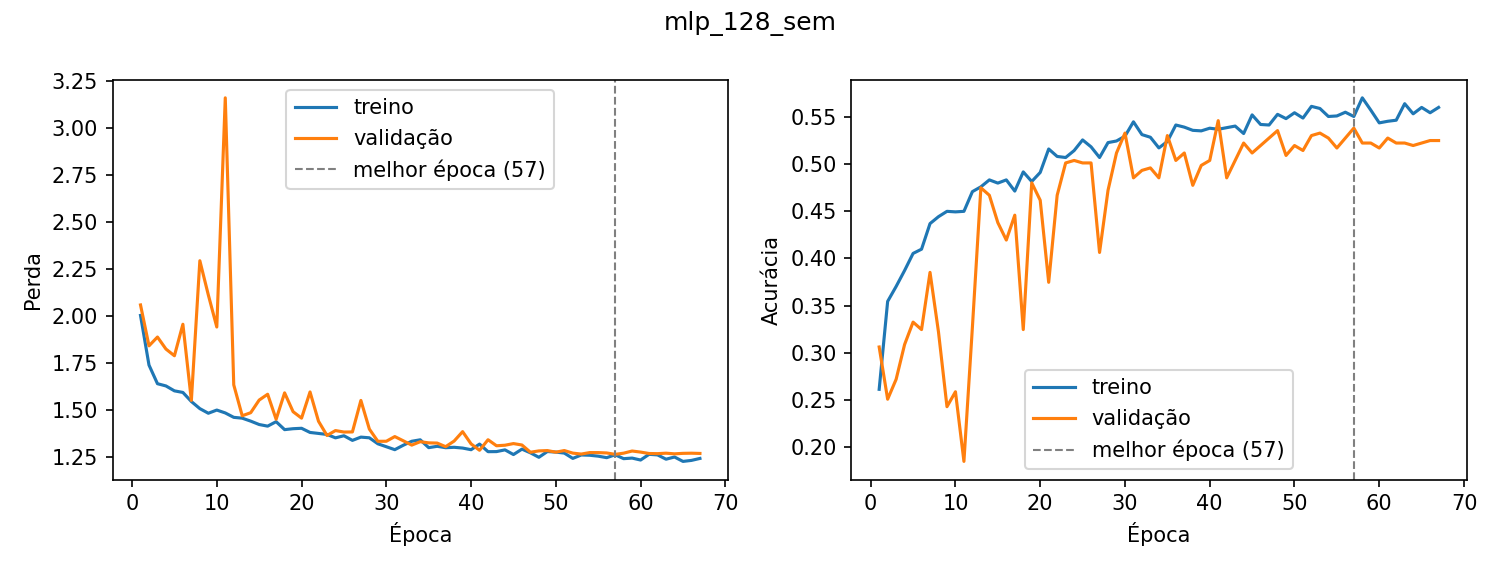

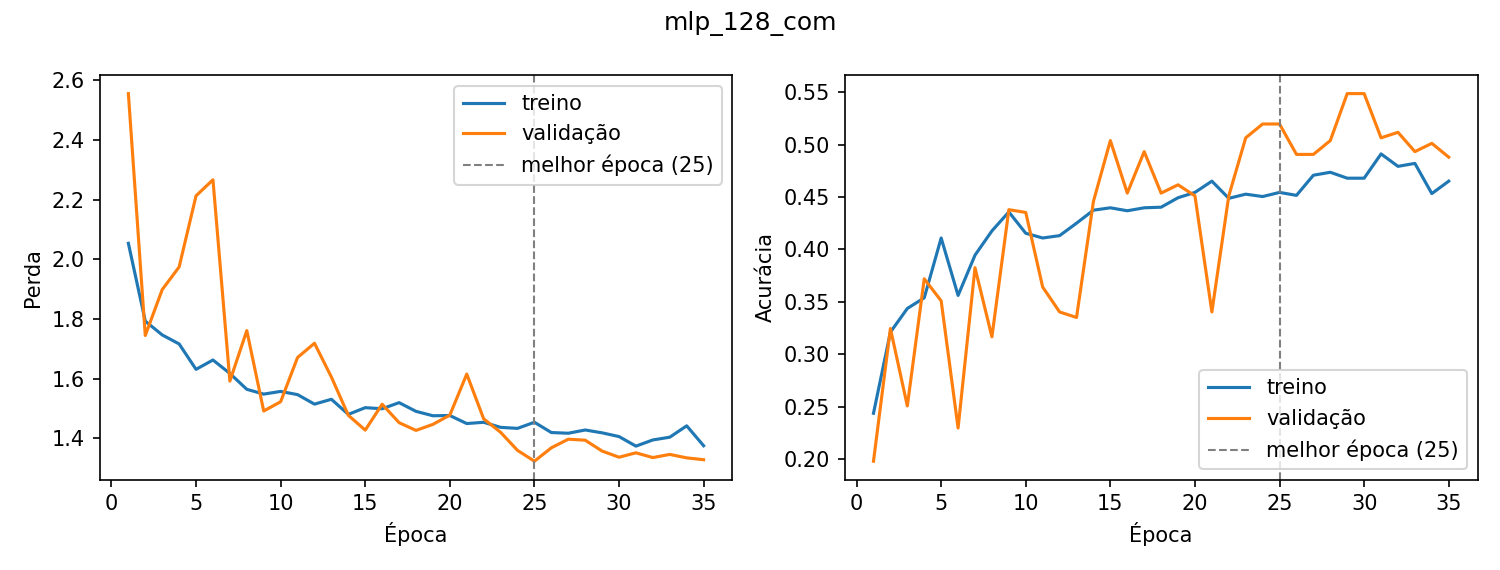

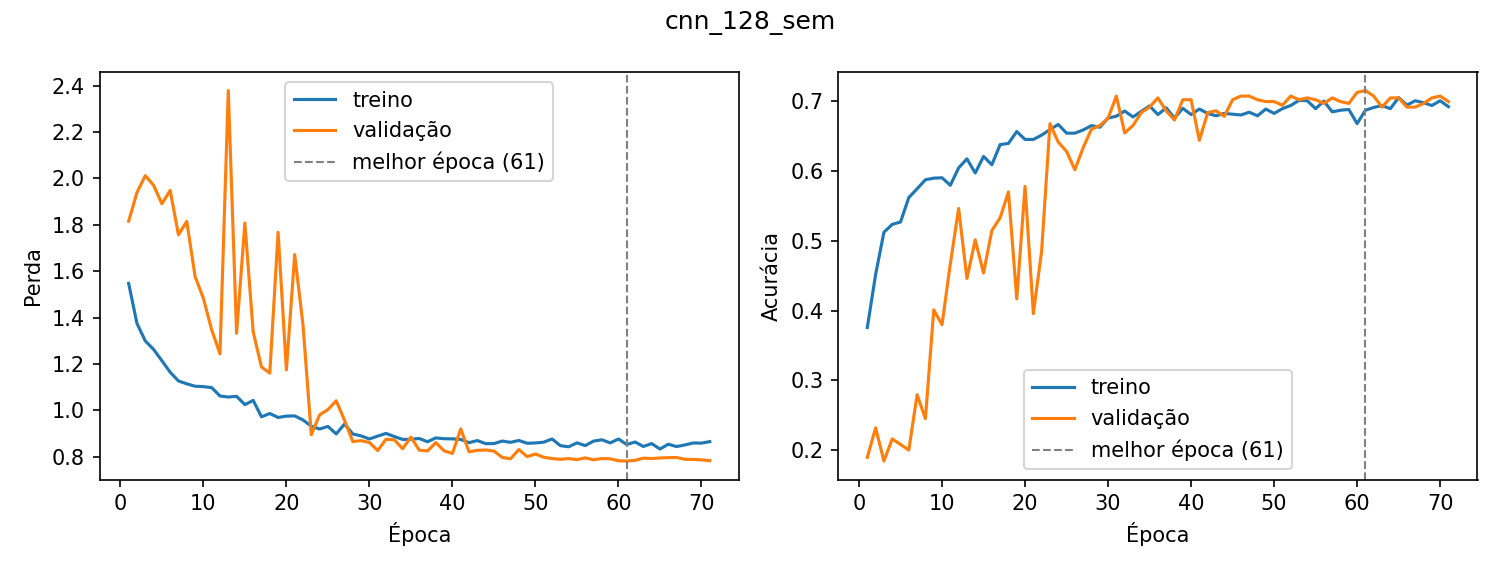

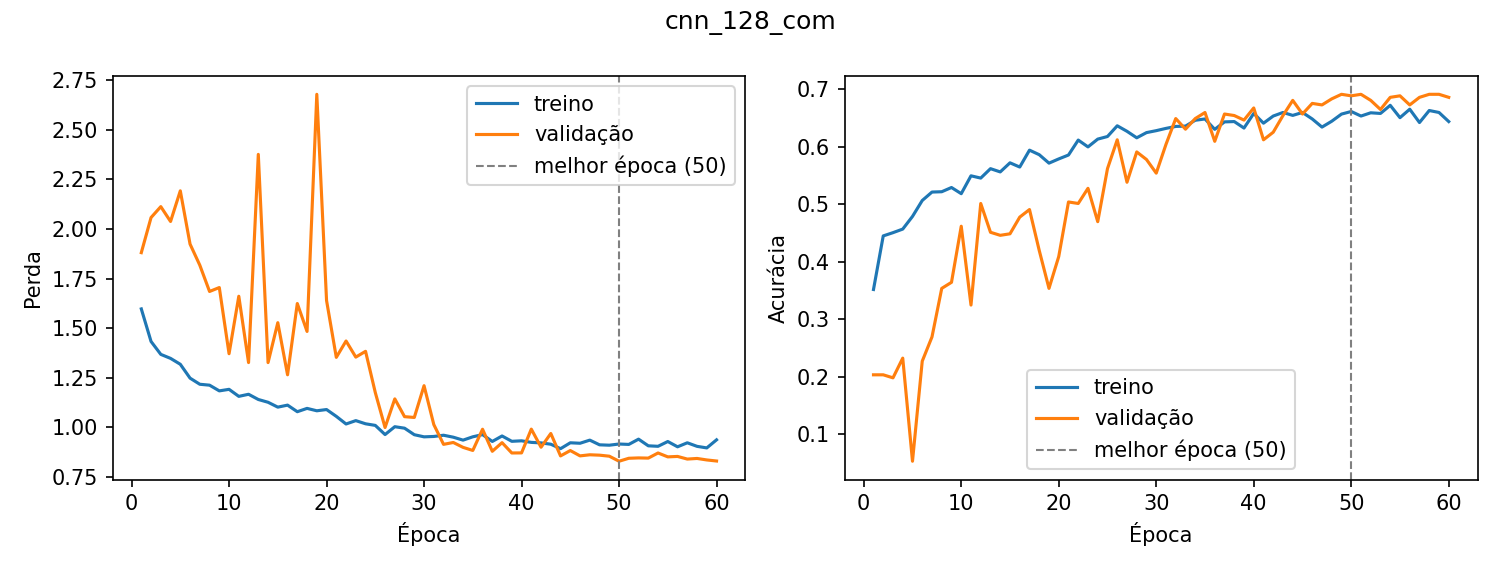

In [12]:
for nome in NOMES:
    p = Path(f'figuras/curvas/{nome}.png')
    if p.exists():
        display(Image(str(p)))